## Task 3: from a dataset to a model

Midterm project, MOP 3231

SEED = 2175

In [28]:
import json
import os

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

SEED = 2175

print("numpy        ", np.__version__)
print("pandas       ", pd.__version__)
print("scikit-learn ", sklearn.__version__)
print("matplotlib   ", matplotlib.__version__)
print("joblib       ", joblib.__version__)

numpy         2.3.4
pandas        2.3.3
scikit-learn  1.7.2
matplotlib    3.10.7
joblib        1.5.2


### Stage 1 · Frame the problem 

The bank can call only the top 10% of a list, so the job is to rank clients: likely answers should end up in that top 10%, and the score is computed before any call.

Metrics: ROC-AUC and average precision for the ranking, then precision@10%, recall and lift for the business side. Accuracy would mislead here: only 11.3% of rows say yes, so "always no" is 88.7% accurate and catches nobody.

`test.csv` lacks two columns of `train.csv`: `y` (the answer) and `duration` (call length). `duration` is known only after the call and it correlates +0.41 with `y`, higher than any usable feature (the numbers are in Stage 2), so I drop it from training too. The model uses the 19 features that exist in both files.

### Stage 2 · Understand the data 

In [29]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("train:", train.shape, "| test:", test.shape)
print("exact duplicate rows in train:", int(train.duplicated().sum()))
print("columns present in train only:", sorted(set(train.columns) - set(test.columns)))
print("columns present in test only: ", sorted(set(test.columns) - set(train.columns)))

train.head(3)

train: (32940, 22) | test: (8236, 20)
exact duplicate rows in train: 0
columns present in train only: ['duration', 'y']
columns present in test only:  []


,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no


First checks pass: 32,940 rows in train against 8,236 in test, no duplicates, and the column difference is exactly `duration` and `y`. The feature list is the 19 columns that exist in both files, without `id`.

In [30]:
y = (train["y"] == "yes").astype(int)

print("counts:", {k: int(v) for k, v in train["y"].value_counts().items()})
print(f"share of yes: {y.mean():.4f}")
print(f"accuracy of always answering 'no': {1 - y.mean():.4f}")

counts: {'no': 29229, 'yes': 3711}
share of yes: 0.1127
accuracy of always answering 'no': 0.8873


Imbalanced target: 3,711 yes against 29,229 no (11.3% and 88.7%). "Always no" scores 88.7% accuracy and catches nobody, so from here on the metrics are about ranking and the top of the list

In [31]:
features = [c for c in train.columns if c not in ("id", "y", "duration")]
cat_cols = [c for c in features if train[c].dtype == "object"]
num_cols = [c for c in features if train[c].dtype != "object"]

print("features:", len(features))
print("categorical:", cat_cols)
print("numeric:", num_cols)

unknown_counts = {c: int((train[c] == "unknown").sum()) for c in cat_cols}
unknown_counts = {c: n for c, n in unknown_counts.items() if n > 0}
print()
print("'unknown' per column:", unknown_counts)
print("total 'unknown' cells:", sum(unknown_counts.values()))

n_pdays = int((train["pdays"] == 999).sum())
n_nonex = int((train["poutcome"] == "nonexistent").sum())
n_prev0 = int((train["previous"] == 0).sum())
print()
print("pdays == 999:", n_pdays, f"({n_pdays / len(train):.1%} of rows)")
print("poutcome == 'nonexistent':", n_nonex)
print("previous == 0:", n_prev0)
print("previous == 0 and poutcome == 'nonexistent' are the same clients:", n_prev0 == n_nonex)
print("pdays 999 but not in that group:", n_pdays - n_prev0)

real_pdays = train["pdays"] != 999
print()
print("yes rate, pdays is a real number:", f"{y[real_pdays].mean():.1%}", f"(n={int(real_pdays.sum()):,})")
print("yes rate, pdays == 999:           ", f"{y[~real_pdays].mean():.1%}", f"(n={int((~real_pdays).sum()):,})")

features: 19
categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
numeric: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

'unknown' per column: {'job': 275, 'marital': 64, 'education': 1401, 'default': 6871, 'housing': 794, 'loan': 794}
total 'unknown' cells: 10199

pdays == 999: 31694 (96.2% of rows)
poutcome == 'nonexistent': 28446
previous == 0: 28446
previous == 0 and poutcome == 'nonexistent' are the same clients: True
pdays 999 but not in that group: 3248

yes rate, pdays is a real number: 63.6% (n=1,246)
yes rate, pdays == 999:            9.2% (n=31,694)


Two things to decide in Stage 4, with counts. `unknown` is a real value in six categorical columns, 10,199 cells in total, most of them in `default` (6,871) and `education` (1,401). And `pdays = 999` (31,694 rows, 96.2%) means "not contacted before": `previous = 0` and `poutcome = "nonexistent"` are the same 28,446 clients and form the bulk of that group; the other 3,248 rows look like source-file inconsistencies. The yes gap is wide: 63.6% for a real `pdays` value (n=1,246) against 9.2% for the 999 group

In [32]:
print("months in the first rows:", train["month"].head(6).tolist())
print("months in the last rows: ", train["month"].tail(6).tolist())
print("mean euribor3m, first 1000 rows:", round(train["euribor3m"].head(1000).mean(), 3))
print("mean euribor3m, last 1000 rows: ", round(train["euribor3m"].tail(1000).mean(), 3))
print("id range:", int(train["id"].min()), "to", int(train["id"].max()))
print("id increases down the file:", bool(train["id"].is_monotonic_increasing))

months in the first rows: ['may', 'aug', 'aug', 'may', 'jun', 'aug']
months in the last rows:  ['jul', 'may', 'jul', 'may', 'jul', 'may']
mean euribor3m, first 1000 rows: 3.634
mean euribor3m, last 1000 rows:  3.612
id range: 0 to 32939
id increases down the file: True


The file is shuffled: the first rows jump between months, `id` is 0 to 32,939 in file order, and `euribor3m` averages the same in the first and last 1,000 rows (3.634 against 3.612). The original campaign order (May 2008 to November 2010) is gone, so row position carries no time information and a random split breaks nothing. The periods themselves still live in the features; Stage 7 comes back to what the random split flatters.

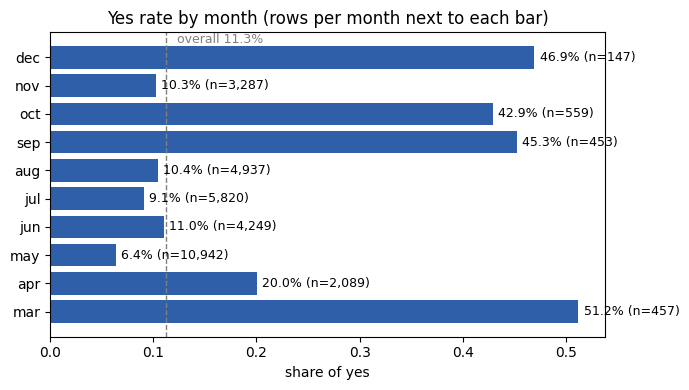

highest: mar 51.2% (n=457)
lowest:  may 6.4% (n=10,942)


In [33]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
by_month = train.groupby("month")["y"].apply(lambda s: (s == "yes").mean()).reindex(month_order).dropna()
n_month = train["month"].value_counts().reindex(month_order).dropna()
overall = y.mean()

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(by_month.index, by_month.values, color="#2f5fa8")
ax.axvline(overall, color="gray", linestyle="--", linewidth=1)
ax.text(overall + 0.01, len(by_month) - 0.5, f"overall {overall:.1%}", color="gray", fontsize=9)
for b, m in zip(bars, by_month.index):
    ax.text(b.get_width() + 0.005, b.get_y() + b.get_height() / 2,
            f"{b.get_width():.1%} (n={int(n_month[m]):,})", va="center", fontsize=9)
ax.set_xlabel("share of yes")
ax.set_title("Yes rate by month (rows per month next to each bar)")
plt.tight_layout()
plt.show()

print("highest:", by_month.idxmax(), f"{by_month.max():.1%}", f"(n={int(n_month[by_month.idxmax()]):,})")
print("lowest: ", by_month.idxmin(), f"{by_month.min():.1%}", f"(n={int(n_month[by_month.idxmin()]):,})")

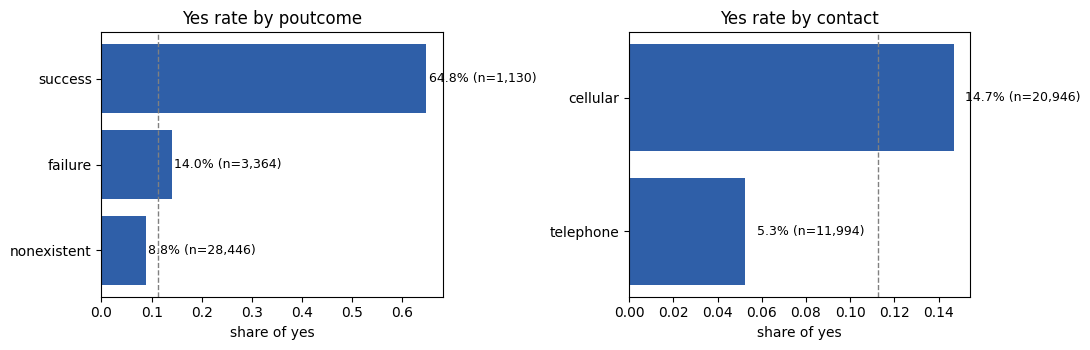

poutcome
failure        0.1403
nonexistent    0.0881
success        0.6478

contact
cellular     0.1470
telephone    0.0526

poutcome counts: {'nonexistent': 28446, 'failure': 3364, 'success': 1130}
contact counts:  {'cellular': 20946, 'telephone': 11994}


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col in zip(axes, ["poutcome", "contact"]):
    g = train.groupby(col)["y"].apply(lambda s: (s == "yes").mean()).sort_values()
    n_g = train[col].value_counts()
    bars = ax.barh(g.index, g.values, color="#2f5fa8")
    ax.axvline(overall, color="gray", linestyle="--", linewidth=1)
    for b, k in zip(bars, g.index):
        ax.text(b.get_width() + 0.005, b.get_y() + b.get_height() / 2,
                f"{b.get_width():.1%} (n={int(n_g[k]):,})", va="center", fontsize=9)
    ax.set_xlabel("share of yes")
    ax.set_title(f"Yes rate by {col}")
plt.tight_layout()
plt.show()

print(train.groupby("poutcome")["y"].apply(lambda s: (s == "yes").mean()).round(4).to_string())
print()
print(train.groupby("contact")["y"].apply(lambda s: (s == "yes").mean()).round(4).to_string())
print()
print("poutcome counts:", {k: int(v) for k, v in train["poutcome"].value_counts().items()})
print("contact counts: ", {k: int(v) for k, v in train["contact"].value_counts().items()})

nr.employed      -0.356
pdays            -0.328
euribor3m        -0.308
emp.var.rate     -0.299
cons.price.idx   -0.134
campaign         -0.065
age               0.032
cons.conf.idx     0.058
previous          0.232
duration          0.408


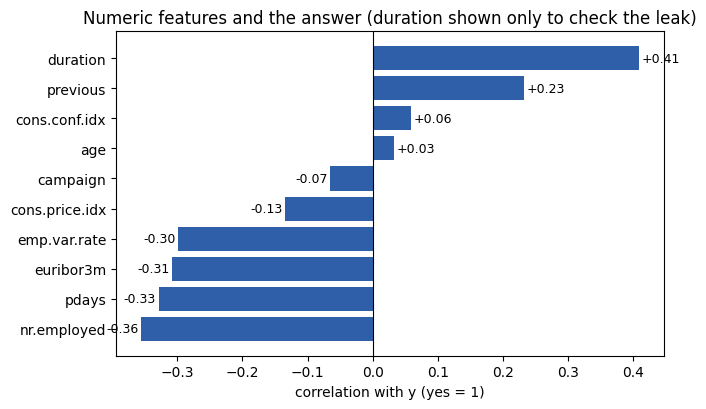

In [35]:
corr = train[num_cols + ["duration"]].corrwith(y).sort_values()
print(corr.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.barh(corr.index, corr.values, color="#2f5fa8")
for b, v in zip(bars, corr.values):
    w = b.get_width()
    ax.text(w + 0.004 if w >= 0 else w - 0.004, b.get_y() + b.get_height() / 2,
            f"{v:+.2f}", va="center", ha="left" if w >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("correlation with y (yes = 1)")
ax.set_title("Numeric features and the answer (duration shown only to check the leak)")
plt.tight_layout()
plt.show()

In [36]:
print("Highest yes rates among larger categories (n >= 500):")
for col in ["job", "education", "marital", "housing", "loan", "default", "day_of_week"]:
    g = train.groupby(col)["y"].agg(rate=lambda s: (s == "yes").mean(), n="size")
    g = g[g["n"] >= 500].sort_values("rate", ascending=False).head(3)
    line = ", ".join(f"{k}: {r:.1%} (n={int(n):,})" for k, r, n in zip(g.index, g["rate"], g["n"]))
    print(f"- {col}: {line}")

Highest yes rates among larger categories (n >= 500):
- job: student: 30.5% (n=692), retired: 25.0% (n=1,375), unemployed: 13.5% (n=792)
- education: unknown: 14.4% (n=1,401), university.degree: 13.7% (n=9,752), professional.course: 11.6% (n=4,155)
- marital: single: 13.8% (n=9,261), married: 10.3% (n=19,965), divorced: 10.1% (n=3,650)
- housing: yes: 11.6% (n=17,301), no: 10.9% (n=14,845), unknown: 10.6% (n=794)
- loan: no: 11.4% (n=27,154), yes: 10.9% (n=4,992), unknown: 10.6% (n=794)
- default: no: 12.9% (n=26,067), unknown: 5.2% (n=6,871)
- day_of_week: thu: 12.1% (n=6,873), tue: 12.1% (n=6,453), wed: 11.6% (n=6,474)


Numbers behind the plots:

1. `poutcome`: "success" 64.8% (n=1,130), "failure" 14.0% (n=3,364), "nonexistent" 8.8% (n=28,446). The strongest visible signal.
2. Month: March 51.2% (n=457), December 46.9% (n=147), September 45.3% (n=453), October 42.9% (n=559), against May 6.4% (n=10,942). The strong months are small and each comes from one campaign wave, so these rates describe the past campaigns and need not repeat.
3. Contact: cellular 14.7% (n=20,946) against telephone 5.3% (n=11,994).
4. `job`: students 30.5% (n=692), retired 25.0% (n=1,375). `default = "unknown"` sits low at 5.2% (n=6,871) against 12.9% for `default = "no"` (n=26,067). `housing`, `loan` and `day_of_week` barely move the rate (10.6% to 12.1%).
5. Numeric correlations are small: -0.36 (`nr.employed`), -0.31 (`euribor3m`), +0.23 (`previous`). `duration` is +0.41, higher than any usable feature, which is why it is excluded.

### Stage 3 · Design the validation

The split is stratified, so the yes share survives in both parts: 6,588 hold-out rows with 742 yes clients (11.3%). Inside dev I use 5 stratified folds with shuffling. The fold-to-fold spread is my ruler: differences smaller than it are noise, and I will not declare a winner inside it.

In [37]:
from sklearn.model_selection import StratifiedKFold, train_test_split

X = train[features]

X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("dev (all decisions happen here):", X_dev.shape, "| yes rate:", round(y_dev.mean(), 4))
print("hold-out (kept aside until the final stage):", X_hold.shape, "| yes count:", int(y_hold.sum()), "| yes rate:", round(y_hold.mean(), 4))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("fold sizes on dev:", [len(te) for _, te in cv.split(X_dev, y_dev)])

dev (all decisions happen here): (26352, 19) | yes rate: 0.1127
hold-out (kept aside until the final stage): (6588, 19) | yes count: 742 | yes rate: 0.1126
fold sizes on dev: [5271, 5271, 5270, 5270, 5270]


### Stage 4 · Preprocess inside a pipeline 

All learning steps (filling, scaling, encoding) sit inside one `Pipeline`, so cross-validation refits them on each fold's training part only. Two open choices are decided here by comparing variants on the same folds with logistic regression as the test model: how to treat `unknown`, and how to treat the `pdays = 999` sentinel

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_plain = [c for c in num_cols if c != "pdays"]


def build_preprocessor(unknown_mode="category", pdays_mode="impute_flag"):
    """ColumnTransformer: scaled numbers, the pdays sentinel handled explicitly, one-hot categories."""
    if unknown_mode == "category":
        cat_part = OneHotEncoder(handle_unknown="ignore")
    elif unknown_mode == "most_frequent":
        cat_part = Pipeline([
            ("fill", SimpleImputer(missing_values="unknown", strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
    else:
        raise ValueError(unknown_mode)

    if pdays_mode == "impute_flag":
        pdays_part = [
            ("pdays", Pipeline([("impute", SimpleImputer(missing_values=999, strategy="median")),
                                ("scale", StandardScaler())]), ["pdays"]),
            ("pdays_was_999", MissingIndicator(missing_values=999), ["pdays"]),
        ]
    elif pdays_mode == "raw":
        pdays_part = [("pdays", StandardScaler(), ["pdays"])]
    else:
        raise ValueError(pdays_mode)

    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num_plain),
        *pdays_part,
        ("cat", cat_part, cat_cols),
    ])


def make_pipeline(model, **prep_kwargs):
    return Pipeline([("prep", build_preprocessor(**prep_kwargs)), ("model", model)])

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate


def cv_frame(estimator, X, y, cv):
    res = cross_validate(
        estimator, X, y, cv=cv, n_jobs=-1,
        scoring={"roc_auc": "roc_auc", "average_precision": "average_precision", "accuracy": "accuracy"},
    )
    return pd.DataFrame({
        "roc_auc": res["test_roc_auc"],
        "average_precision": res["test_average_precision"],
        "accuracy": res["test_accuracy"],
    })


def summarize(estimator, X, y, cv, name):
    frame = cv_frame(estimator, X, y, cv)
    row = {"model": name}
    for metric in frame.columns:
        row[metric + " mean"] = round(float(frame[metric].mean()), 4)
        row[metric + " std"] = round(float(frame[metric].std()), 4)
    row["roc_auc folds"] = " / ".join(f"{v:.4f}" for v in frame["roc_auc"])
    return pd.DataFrame([row])


variants = {
    "chosen: 'unknown' as its own category; pdays 999 filled + flag": {},
    "other: 'unknown' filled with the most frequent value": {"unknown_mode": "most_frequent"},
    "other: pdays 999 kept as a raw number": {"pdays_mode": "raw"},
}
prep_table = pd.concat(
    [summarize(make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED), **kwargs),
               X_dev, y_dev, cv, name)
     for name, kwargs in variants.items()],
    ignore_index=True,
)
print(prep_table.to_string(index=False))

                                                         model  roc_auc mean  roc_auc std  average_precision mean  average_precision std  accuracy mean  accuracy std                              roc_auc folds
chosen: 'unknown' as its own category; pdays 999 filled + flag          0.79       0.0103                  0.4507                 0.0193         0.8999        0.0020 0.7957 / 0.7942 / 0.7716 / 0.7930 / 0.7954
          other: 'unknown' filled with the most frequent value          0.79       0.0108                  0.4506                 0.0197         0.8999        0.0023 0.7962 / 0.7955 / 0.7709 / 0.7952 / 0.7924
                         other: pdays 999 kept as a raw number          0.79       0.0104                  0.4516                 0.0189         0.9000        0.0019 0.7959 / 0.7943 / 0.7716 / 0.7932 / 0.7952


In [40]:
fold_train_idx, fold_test_idx = next(iter(cv.split(X_dev, y_dev)))

pipe_demo = make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED))
pipe_demo.fit(X_dev.iloc[fold_train_idx], y_dev.iloc[fold_train_idx])
scaler = pipe_demo.named_steps["prep"].named_transformers_["num"].named_steps["scale"]

age_position = num_plain.index("age")
print("rows in the fold-1 training part:", len(fold_train_idx))
print("rows the scaler was fitted on:    ", int(scaler.n_samples_seen_))
print("rows in the whole dev set:        ", len(X_dev))
print("scaler mean for age:", round(float(scaler.mean_[age_position]), 4))
print("whole-dev mean for age:", round(float(X_dev["age"].mean()), 4))

rows in the fold-1 training part: 21081
rows the scaler was fitted on:     21081
rows in the whole dev set:         26352
scaler mean for age: 40.0491
whole-dev mean for age: 40.056


Verdict from the comparison (mean ± std over the 5 folds):

- `unknown` as its own category: AUC 0.79 ± 0.0103, average precision 0.4507 ± 0.0193. Filling it with the most frequent value: AUC 0.79 ± 0.0108, average precision 0.4506 ± 0.0197. The difference in average precision is 0.0001, far inside the fold spread; on AUC the two are the same to two decimals. Cross-validation cannot crown either variant here.
- `pdays`: replacing 999 with the median plus the "was 999" flag: AUC 0.79 ± 0.0103, average precision 0.4507 ± 0.0193. Keeping 999 as a raw number: AUC 0.79 ± 0.0104, average precision 0.4516 ± 0.0189, which is 0.0009 above the chosen variant and still inside the noise.

Neither choice costs or earns anything measurable, so I keep them for the meaning they carry, not for the decimals. `unknown` stays its own category because the level behaves differently from the others (default = "unknown" sits at 5.2% yes against 12.9% for "no", Stage 2), and filling 10,199 cells with the most frequent value would erase that. `pdays = 999` becomes a flag because 999 is a code for "never contacted", not a distance in days, and the extra column states that reading explicitly.

The folding question is answered with numbers as well: the scaler fitted on the first fold reports 21,081 training rows against 26,352 in the whole dev set, and an age mean of 40.0491 against 40.056. Nothing is fitted outside the training folds.

### Stage 5 · Baselines 

The bar for every candidate model, on the same folds: a majority-class model and a simple logistic regression in the full pipeline. Watch the accuracy column of the majority model; it looks good while the model knows nothing.


In [41]:
from sklearn.dummy import DummyClassifier

baseline_rows = []
for name, estimator in {
    "majority class (always 'no')": DummyClassifier(strategy="most_frequent"),
    "logistic regression, default C": make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED)),
}.items():
    baseline_rows.append(summarize(estimator, X_dev, y_dev, cv, name))

baseline_table = pd.concat(baseline_rows, ignore_index=True)
print(baseline_table.to_string(index=False))

                         model  roc_auc mean  roc_auc std  average_precision mean  average_precision std  accuracy mean  accuracy std                              roc_auc folds
  majority class (always 'no')          0.50       0.0000                  0.1127                 0.0001         0.8873        0.0001 0.5000 / 0.5000 / 0.5000 / 0.5000 / 0.5000
logistic regression, default C          0.79       0.0103                  0.4507                 0.0193         0.8999        0.0020 0.7957 / 0.7942 / 0.7716 / 0.7930 / 0.7954


The numbers do their job here. The majority class is 88.7% accurate while its AUC is 0.50, because saying "no" is right 88.7% of the time and the ranking is hopeless. The simple logistic regression already ranks at AUC 0.79 and average precision 0.4507. So the model to beat is the simple logistic regression, and accuracy is not the metric that decides anything.

### Stage 6 · Compare models and tune 

Four families from the course, each inside the same pipeline and on the same folds: logistic regression, KNN, a decision tree and a random forest. Hyper-parameters are tuned by grid search on dev only (the spaces are in the code), then class weighting is checked, and only after that can a winner be named, and only if the difference is bigger than the noise.

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

searches = {
    "logistic regression": (
        make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED)),
        {"model__C": [0.1, 1, 10]},
    ),
    "KNN": (
        make_pipeline(KNeighborsClassifier()),
        {"model__n_neighbors": [15, 31, 51]},
    ),
    "decision tree": (
        make_pipeline(DecisionTreeClassifier(random_state=SEED)),
        {"model__max_depth": [4, 6, 8, 12], "model__min_samples_leaf": [1, 10]},
    ),
    "random forest": (
        make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED)),
        {"model__max_depth": [None, 16], "model__min_samples_leaf": [1, 5]},
    ),
}

fitted = {}
model_rows = []
for name, (pipe, grid) in searches.items():
    gs = GridSearchCV(pipe, grid, cv=cv, n_jobs=-1, refit="roc_auc",
                      scoring={"roc_auc": "roc_auc", "average_precision": "average_precision"})
    gs.fit(X_dev, y_dev)
    fitted[name] = gs
    i = gs.best_index_
    model_rows.append({
        "model": name,
        "best params": {k.replace("model__", ""): str(v) for k, v in gs.best_params_.items()},
        "roc_auc mean": round(float(gs.cv_results_["mean_test_roc_auc"][i]), 4),
        "roc_auc std": round(float(gs.cv_results_["std_test_roc_auc"][i]), 4),
        "average_precision mean": round(float(gs.cv_results_["mean_test_average_precision"][i]), 4),
        "average_precision std": round(float(gs.cv_results_["std_test_average_precision"][i]), 4),
    })

comp = pd.DataFrame(model_rows)
print(comp.to_string(index=False))
print()
for name, gs in fitted.items():
    i = gs.best_index_
    folds = [round(float(gs.cv_results_[f"split{s}_test_roc_auc"][i]), 4) for s in range(cv.get_n_splits())]
    print(f"{name}: ROC-AUC per fold {folds}")

              model                                  best params  roc_auc mean  roc_auc std  average_precision mean  average_precision std
logistic regression                                   {'C': '1'}        0.7900       0.0092                  0.4507                 0.0173
                KNN                        {'n_neighbors': '51'}        0.7718       0.0086                  0.4166                 0.0254
      decision tree {'max_depth': '6', 'min_samples_leaf': '10'}        0.7823       0.0067                  0.4104                 0.0106
      random forest {'max_depth': '16', 'min_samples_leaf': '5'}        0.7968       0.0102                  0.4686                 0.0172

logistic regression: ROC-AUC per fold [0.7957, 0.7942, 0.7716, 0.793, 0.7954]
KNN: ROC-AUC per fold [0.7854, 0.7652, 0.7601, 0.7738, 0.7742]
decision tree: ROC-AUC per fold [0.7836, 0.7908, 0.7723, 0.7874, 0.7776]
random forest: ROC-AUC per fold [0.8142, 0.8011, 0.7849, 0.7892, 0.7948]


In [43]:
best_C = fitted["logistic regression"].best_params_["model__C"]
best_rf = {k.replace("model__", ""): v for k, v in fitted["random forest"].best_params_.items()}

imbalance_rows = []
for name, estimator in {
    "logistic regression": make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED, C=best_C)),
    "logistic regression + class weights": make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED, C=best_C, class_weight="balanced")),
    "random forest": make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED, **best_rf)),
    "random forest + class weights": make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED, class_weight="balanced_subsample", **best_rf)),
}.items():
    imbalance_rows.append(summarize(estimator, X_dev, y_dev, cv, name))

imbalance_table = pd.concat(imbalance_rows, ignore_index=True)
print(imbalance_table.to_string(index=False))

                              model  roc_auc mean  roc_auc std  average_precision mean  average_precision std  accuracy mean  accuracy std                              roc_auc folds
                logistic regression        0.7900       0.0103                  0.4507                 0.0193         0.8999         0.002 0.7957 / 0.7942 / 0.7716 / 0.7930 / 0.7954
logistic regression + class weights        0.7907       0.0098                  0.4456                 0.0178         0.8307         0.004 0.7984 / 0.7952 / 0.7736 / 0.7922 / 0.7939
                      random forest        0.7968       0.0114                  0.4686                 0.0193         0.9008         0.004 0.8142 / 0.8011 / 0.7849 / 0.7892 / 0.7948
      random forest + class weights        0.7968       0.0117                  0.4658                 0.0223         0.8672         0.005 0.8134 / 0.8006 / 0.7824 / 0.7898 / 0.7976


In [44]:
comp_sorted = comp.sort_values("average_precision mean", ascending=False).reset_index(drop=True)
top = comp_sorted.iloc[0]
runner_up = comp_sorted.iloc[1]

print(f"best by average precision: {top['model']} ({top['average_precision mean']:.4f})")
print(f"next: {runner_up['model']} ({runner_up['average_precision mean']:.4f})")
print(f"gap {top['average_precision mean'] - runner_up['average_precision mean']:.4f}; "
      f"typical fold std of the best model {top['average_precision std']:.4f}")
print(f"ROC-AUC gap {top['roc_auc mean'] - runner_up['roc_auc mean']:.4f}; "
      f"std {top['roc_auc std']:.4f} against {runner_up['roc_auc std']:.4f}")

winner = top["model"]
final_pipe = fitted[winner].best_estimator_
print()
print("chosen for the final stage:", winner, "with", fitted[winner].best_params_)

best by average precision: random forest (0.4686)
next: logistic regression (0.4507)
gap 0.0179; typical fold std of the best model 0.0172
ROC-AUC gap 0.0068; std 0.0102 against 0.0092

chosen for the final stage: random forest with {'model__max_depth': 16, 'model__min_samples_leaf': 5}


Reading the two tables:

- Best mean average precision: the random forest at 0.4686, then logistic regression at 0.4507. The gap of 0.0179 is about one fold spread of the forest (0.0172), and on ROC-AUC the gap (0.0068) is smaller than both spreads (0.0102 against 0.0092), so this is a lead, not a declared win. KNN (0.4166) and the decision tree (0.4104) sit more than two spreads behind and are clearly out.
- Class weights compared with doing nothing: ROC-AUC is essentially unchanged (0.7900 against 0.7907 for logistic regression; 0.7968 on both sides for the forest), average precision moves down slightly (0.4507 to 0.4456; 0.4686 to 0.4658), and accuracy falls from about 0.90 to 0.83 and 0.87, since balanced models call more clients. Every move here is inside the fold spread, so balancing earns nothing on this data and the unweighted versions stay.

The random forest goes into the final stage: it leads on both ranking metrics and nothing else comes close to it. Its edge over logistic regression is itself the size of the fold spread, so I treat it as the mild favourite, not as a proven winner.

### Stage 7 · Final evaluation, once 

The hold-out appears for the first time here, after all choices are fixed. First the ranking quality with ROC and precision-recall curves, then the capacity rule: call the top 10% and read the confusion matrix in plain language.

In [45]:
from sklearn.metrics import average_precision_score, roc_auc_score

hold_scores = final_pipe.predict_proba(X_hold)[:, 1]
hold_auc = roc_auc_score(y_hold, hold_scores)
hold_ap = average_precision_score(y_hold, hold_scores)

print(f"hold-out ROC-AUC: {hold_auc:.4f}")
print(f"hold-out average precision: {hold_ap:.4f}")
print(f"yes rate on the hold-out (precision of calling at random): {y_hold.mean():.4f}")

hold-out ROC-AUC: 0.8071
hold-out average precision: 0.4825
yes rate on the hold-out (precision of calling at random): 0.1126


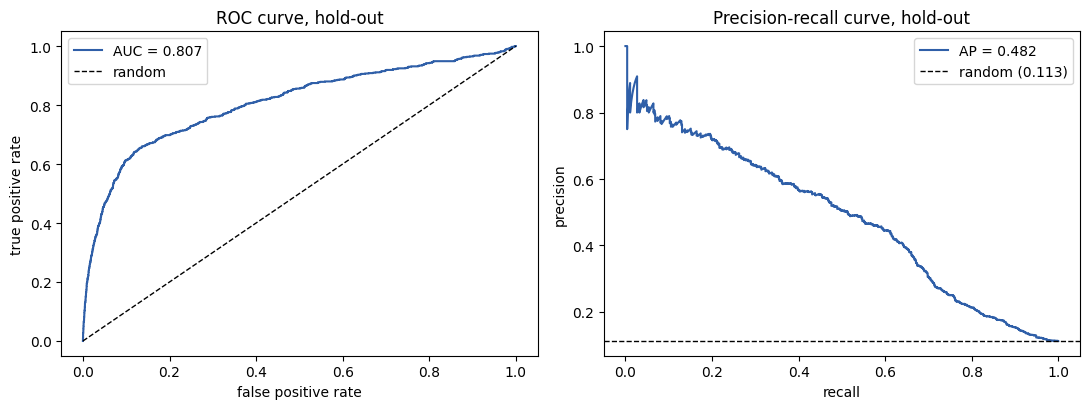

In [46]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

fpr, tpr, _ = roc_curve(y_hold, hold_scores)
axes[0].plot(fpr, tpr, color="#2f5fa8", label=f"AUC = {hold_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="random")
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curve, hold-out")
axes[0].legend()

prec, rec, _ = precision_recall_curve(y_hold, hold_scores)
axes[1].plot(rec, prec, color="#2f5fa8", label=f"AP = {hold_ap:.3f}")
axes[1].axhline(y_hold.mean(), color="k", linestyle="--", linewidth=1, label=f"random ({y_hold.mean():.3f})")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curve, hold-out")
axes[1].legend()

plt.tight_layout()
plt.show()

In [47]:
from sklearn.metrics import confusion_matrix

n_hold = len(y_hold)
n_calls = int(round(0.10 * n_hold))
threshold = np.sort(hold_scores)[::-1][n_calls - 1]
hold_pred = (hold_scores >= threshold).astype(int)
called = int(hold_pred.sum())

cm = confusion_matrix(y_hold, hold_pred)
tn, fp, fn, tp = cm.ravel()
precision = tp / (tp + fp)
recall = tp / (tp + fn)
lift = precision / y_hold.mean()

print(f"capacity rule: call {n_calls} of {n_hold} clients, score cutoff {threshold:.4f}")
print(f"called with this cutoff: {called}")
print(f"precision {precision:.3f} | recall {recall:.3f} | lift over random {lift:.2f}x")
print(f"random calls of the same size hit about {n_calls * y_hold.mean():.0f} yes clients; this list hits {tp}")
print()
print("confusion matrix (rows = true answer, columns = our decision):")
print(pd.DataFrame(cm, index=["true no", "true yes"], columns=["no call (0)", "call (1)"]))

capacity rule: call 659 of 6588 clients, score cutoff 0.3470
called with this cutoff: 659
precision 0.531 | recall 0.472 | lift over random 4.72x
random calls of the same size hit about 74 yes clients; this list hits 350

confusion matrix (rows = true answer, columns = our decision):
          no call (0)  call (1)
true no          5537       309
true yes          392       350


- Ranking: the hold-out gives ROC-AUC 0.8071 and average precision 0.4825, against a base rate of 0.1126. Both land slightly above their cross-validation values (0.7968 ± 0.0102 and 0.4686 ± 0.0172), well inside one fold spread.
- Capacity rule: the 10% cut calls 659 clients; 350 of them said yes (precision 0.531), which is 4.72 times what calling at random finds (about 74 yes clients). The list catches 350 of the 742 yes clients (recall 0.472) and misses 392.
- For the call centre in one sentence: of every 100 clients the model tells us to call, roughly 53 say yes, against 11 when the list is called blindly.
- Honest note: this split is random, so the model is scored on the same campaign periods it learned from. Live use means training on the past and calling into the future with different economic conditions, so 0.8071 is optimistic; Stage 2 already showed how strongly the month and the economy move the answer.

### Stage 8 · Save and describe the model

Last steps: refit the chosen pipeline on all of `train.csv`, save it with `joblib`, and write `predictions.csv` for `test.csv` with the top-10% rule. The pipeline contains only scikit-learn parts, so it loads in a fresh Python process from the repository root

In [48]:
import os

from sklearn.base import clone

X_full = train[features]
final_model = clone(final_pipe)
final_model.fit(X_full, y)

joblib.dump(final_model, "model.joblib")
print(f"saved model.joblib, {os.path.getsize('model.joblib') / 1e6:.1f} MB (limit is 50 MB)")
print("fitted on all", len(X_full), "rows")

saved model.joblib, 37.9 MB (limit is 50 MB)
fitted on all 32940 rows


In [49]:
test_features = test.drop(columns="id")
test_scores = final_model.predict_proba(test_features)[:, 1]

n_test_calls = int(round(0.10 * len(test_scores)))
test_cutoff = np.sort(test_scores)[::-1][n_test_calls - 1]
test_pred = (test_scores >= test_cutoff).astype(int)

predictions = pd.DataFrame({"id": test["id"], "y_pred": test_pred, "y_score": test_scores})
predictions.to_csv("predictions.csv", index=False)

print(predictions.head())
print("rows:", len(predictions), "| y_pred = 1:", int(test_pred.sum()), f"({test_pred.mean():.1%})")
print("ids match test.csv:", bool((predictions["id"] == test["id"]).all()))
print("y_score range:", round(float(test_scores.min()), 6), "to", round(float(test_scores.max()), 6))

      id  y_pred   y_score
0  32940       0  0.033099
1  32941       0  0.049013
2  32942       0  0.050084
3  32943       0  0.084541
4  32944       0  0.048268
rows: 8236 | y_pred = 1: 824 (10.0%)
ids match test.csv: True
y_score range: 0.010791 to 0.898559


### Files produced by this notebook


`model.joblib` holds the fitted pipeline (36.1 MB); `predictions.csv` has `id, y_pred, y_score` for all 8,236 test rows, with 824 clients (10.0%) marked to call; `REPORT.md` is the model card. I also opened a fresh terminal in the repository root and checked `python -c "import joblib; joblib.load('model.joblib')"` plus a few scored rows of `test.csv`